<div style="background:#2E7D32;color:white;padding:18px 22px;border-radius:10px;border-bottom:5px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/algoprofessor-ai-scientist/main/assets/logo_transparent.png" alt="Algo Professor" style="float:right;height:74px;background:white;border-radius:8px;padding:4px 8px">
<div style="font-size:13px;letter-spacing:2px;color:#F6EBC4">ALGOPROFESSOR · AI SCIENTIST HANDS-ON · SUNDAY 4</div>
<div style="font-size:28px;font-weight:bold;margin-top:4px">Embeddings, Retrieval & RAG</div>
<div style="font-size:15px;margin-top:6px">Hours 16–20 · 2 h hands-on teaching + 3 h real-time project work · GitHub submission by 18:00</div>
</div>

| Hour | Mode | Focus | Dataset |
|---|---|---|---|
| 16 | TEACH | Embeddings, vector search, FAISS (Flat, IVF, HNSW) | SST-2 sentences as a search corpus |
| 17 | TEACH | Hybrid BM25 + dense retrieval, re-ranking, Recall@k / MRR / nDCG | TruthfulQA (790 questions, hard negatives) |
| 18 | BUILD | PolicyGPT: PDF ingestion, chunking with page metadata | Course syllabus PDF (20 pages) |
| 19 | BUILD | Cited Q&A API with abstention (FastAPI) | Same corpus |
| 20 | BUILD | Evaluation: dev set to tune, golden set to test, faithfulness, abstention | 8-question dev set + 25-question golden set |

> **About the documents.** In class, PolicyGPT ingests NEP 2020 and UGC/AICTE regulation PDFs. This executed copy uses
> the course syllabus PDF from this repository so every answer can be checked by you. The pipeline is identical.

In [1]:
# ---------- Setup (run once) ----------
import os, pathlib, urllib.request, warnings, time, json, random
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Data cache lives at the repository root (data/ is git-ignored); figures go next to the notes.
DATA = pathlib.Path(os.environ.get("AP_DATA", "../../data")); DATA.mkdir(parents=True, exist_ok=True)
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)

def fetch(url, name):
    """Download a file once into the shared data cache and return its path."""
    p = DATA / name
    if not p.exists():
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(url, p)
    return p

# AlgoProfessor colour palette
NAVY, GOLD, GREEN, PURPLE = "#0B1F3A", "#C9A227", "#1E7B5A", "#6A3D9A"
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "Nimbus Roman", "DejaVu Serif"],
                     "axes.edgecolor": NAVY, "axes.labelcolor": NAVY, "xtick.color": NAVY, "ytick.color": NAVY,
                     "axes.titleweight": "bold", "axes.titlecolor": NAVY, "figure.dpi": 110,
                     "axes.prop_cycle": plt.cycler(color=[NAVY, GOLD, GREEN, PURPLE, "#A4243B", "#C25E00"])})
print("Setup complete. Data cache:", DATA.resolve())

Setup complete. Data cache: /home/claude/build/data


In [2]:
import re, math, collections
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
import faiss
from rank_bm25 import BM25Okapi
print("faiss", faiss.__version__)

faiss 1.16.0


---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 16 — Embeddings and vector search with FAISS

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">SST-2 sentences (8,741) as a search corpus</span>
**Skills:** <span style="color:#6A3D9A">Embeddings, vector DBs, ANN indexing (IVF, HNSW)</span>

An **embedding** maps text to a vector so that similar meanings land close together. Here we build embeddings with
**LSA** (TF-IDF → truncated SVD), which needs no download. In class, swap in a sentence-transformer
(`all-MiniLM-L6-v2`) — the FAISS code stays the same.

In [3]:
sst = pd.concat([pd.read_csv(fetch("https://raw.githubusercontent.com/clairett/pytorch-sentiment-classification/master/data/SST2/train.tsv", "sst2_train.tsv"), sep="\t", header=None, names=["text", "label"]),
                 pd.read_csv(fetch("https://raw.githubusercontent.com/clairett/pytorch-sentiment-classification/master/data/SST2/test.tsv", "sst2_test.tsv"), sep="\t", header=None, names=["text", "label"])], ignore_index=True)
docs = sst.text.tolist()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")
svd = TruncatedSVD(256, random_state=SEED)
E = normalize(svd.fit_transform(tfidf.fit_transform(docs))).astype("float32")
embed = lambda qs: normalize(svd.transform(tfidf.transform(qs))).astype("float32")
print("corpus:", len(docs), "| embedding dim:", E.shape[1])

corpus: 8741 | embedding dim: 256


In [4]:
d = E.shape[1]
flat = faiss.IndexFlatIP(d); flat.add(E)                                  # exact search (cosine via inner product)
quant = faiss.IndexFlatIP(d); ivf = faiss.IndexIVFFlat(quant, d, 64, faiss.METRIC_INNER_PRODUCT)
ivf.train(E); ivf.add(E); ivf.nprobe = 6                                   # search only 6 of 64 clusters
hnsw = faiss.IndexHNSWFlat(d, 32, faiss.METRIC_INNER_PRODUCT); hnsw.add(E)   # graph-based ANN

Q = embed(sst.text.sample(500, random_state=SEED).tolist())
def timed(index):
    t0 = time.perf_counter(); _, I = index.search(Q, 10); return I, (time.perf_counter() - t0) / len(Q) * 1e6
I_flat, t_flat = timed(flat); rows = [{"index": "Flat (exact)", "recall@10 vs exact": 1.0, "µs / query": round(t_flat, 1)}]
for name, idx in [("IVF (64 lists, nprobe=6)", ivf), ("HNSW (M=32)", hnsw)]:
    I, t = timed(idx); rec = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(I, I_flat)])
    rows.append({"index": name, "recall@10 vs exact": round(rec, 3), "µs / query": round(t, 1)})
pd.DataFrame(rows)

,index,recall@10 vs exact,µs / query
0,Flat (exact),1.000,465.6
1,"IVF (64 lists, nprobe=6)",0.842,47.0
2,HNSW (M=32),0.980,43.6


In [5]:
for q in ["a heartwarming film for the whole family", "boring and far too long"]:
    _, I = flat.search(embed([q]), 3)
    print(f"QUERY: {q}"); [print("   ->", docs[i][:95]) for i in I[0]]; print()

QUERY: a heartwarming film for the whole family
   -> a film that will enthrall the whole family
   -> a fleet footed and pleasingly upbeat family diversion
   -> family fare

QUERY: boring and far too long
   -> boring and meandering
   -> a boring , formulaic mix of serial killers and stalk 'n' slash
   -> godawful boring slug of a movie



At 8.7k vectors exact search is already fast. ANN indexes matter at millions of vectors: IVF scans a few clusters,
HNSW walks a graph — trading a little recall for large speed-ups. **Chroma** and **pgvector** wrap the same ideas with
storage, metadata filters and SQL.

---
<span style="background:#C9A227;color:#0B1F3A;padding:3px 9px;border-radius:4px;font-weight:bold">TEACH</span>
## Hour 17 — Hybrid retrieval, re-ranking and retrieval metrics

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">TruthfulQA (790 questions with best and best-incorrect answers)</span>
**Skills:** <span style="color:#6A3D9A">BM25 + dense hybrid, re-rankers, Recall@k, MRR, nDCG</span>

**Task:** for each question, retrieve its *best (true) answer* from a corpus that also contains every question's
*best incorrect answer* — a hard negative that often uses the same words. This shows why retrieval ≠ truth.

In [6]:
tqa = pd.read_csv(fetch("https://raw.githubusercontent.com/sylinrl/TruthfulQA/main/TruthfulQA.csv", "TruthfulQA.csv"))
corpus = tqa["Best Answer"].tolist() + tqa["Best Incorrect Answer"].tolist()
nQ = len(tqa); questions = tqa.Question.tolist()
print("questions:", nQ, "| corpus documents:", len(corpus))
tok = lambda s: re.findall(r"[a-z0-9]+", s.lower())
bm25 = BM25Okapi([tok(c) for c in corpus])
tf2 = TfidfVectorizer(sublinear_tf=True, stop_words="english").fit(corpus + questions)
sv2 = TruncatedSVD(200, random_state=SEED).fit(tf2.transform(corpus + questions))
emb2 = lambda xs: normalize(sv2.transform(tf2.transform(xs)))
C2, Q2 = emb2(corpus), emb2(questions)
S_bm25 = np.array([bm25.get_scores(tok(q)) for q in questions])
S_dense = Q2 @ C2.T

questions: 790 | corpus documents: 1580


In [7]:
def rrf(*score_mats, k=60):
    """Reciprocal-rank fusion: add 1/(k + rank) from each retriever."""
    out = np.zeros_like(score_mats[0])
    for S in score_mats:
        ranks = (-S).argsort(1).argsort(1); out += 1.0 / (k + ranks + 1)
    return out

def metrics(S, rows=None):
    rows = np.arange(nQ) if rows is None else rows
    rank = np.array([(S[i] > S[i, i]).sum() + 1 for i in rows])          # gold doc for question i is corpus[i]
    wrong_top1 = np.mean([S[i].argmax() == nQ + i for i in rows])         # its own misconception ranked first
    return {"Recall@1": np.mean(rank <= 1), "Recall@5": np.mean(rank <= 5), "MRR": np.mean(1 / rank),
            "nDCG@10": np.mean([1 / np.log2(r + 1) if r <= 10 else 0 for r in rank]), "misconception@1": wrong_top1}

S_hybrid = rrf(S_bm25, S_dense)
res17 = pd.DataFrame({name: metrics(S) for name, S in [("BM25", S_bm25), ("Dense (LSA)", S_dense), ("Hybrid (RRF)", S_hybrid)]}).T.round(3)
res17

,Recall@1,Recall@5,MRR,nDCG@10,misconception@1
BM25,0.377,0.772,0.567,0.625,0.471
Dense (LSA),0.384,0.737,0.547,0.600,0.381
Hybrid (RRF),0.462,0.772,0.609,0.657,0.362


In [8]:
# A learned re-ranker over the top-20 hybrid candidates (stand-in for a cross-encoder): train on half the questions, test on the other half
from sklearn.linear_model import LogisticRegression
NEG = re.compile(r"\b(no|not|nothing|never|none|cannot|can't|don't|doesn't|isn't|aren't|won't|there is no)\b")
def feats(i, j):
    q, c = set(tok(questions[i])), set(tok(corpus[j]))
    return [S_bm25[i, j] / (S_bm25[i].max() + 1e-9), S_dense[i, j], len(q & c) / (len(q) + 1),
            len(corpus[j].split()), float(bool(NEG.search(corpus[j].lower())))]
idx = np.random.RandomState(SEED).permutation(nQ); train_q, test_q = idx[: nQ // 2], idx[nQ // 2:]
cand = {i: np.argsort(-S_hybrid[i])[:20] for i in range(nQ)}
Xr, yr = [], []
for i in train_q:
    for j in cand[i]: Xr.append(feats(i, j)); yr.append(int(j == i))
rr = LogisticRegression(max_iter=2000).fit(Xr, yr)
S_rerank = S_hybrid.copy() * 0 - 1e9
for i in range(nQ):
    S_rerank[i, cand[i]] = rr.decision_function([feats(i, j) for j in cand[i]])
res17b = pd.DataFrame({"Hybrid (test half)": metrics(S_hybrid, test_q), "Hybrid + re-ranker (test half)": metrics(S_rerank, test_q)}).T.round(3)
print("re-ranker weights [bm25, dense, overlap, length, negation]:", rr.coef_.round(2)); res17b

re-ranker weights [bm25, dense, overlap, length, negation]: [[3.94 3.41 0.82 0.05 1.05]]


,Recall@1,Recall@5,MRR,nDCG@10,misconception@1
Hybrid (test half),0.468,0.767,0.610,0.655,0.342
Hybrid + re-ranker (test half),0.423,0.767,0.595,0.639,0.405


**Always check a re-ranker on held-out questions.** Hand-made features (scores, word overlap, length, negation) cannot
tell a true statement from a fluent false one, so they may not beat the hybrid at all — compare the two rows above.
Real systems use a **cross-encoder** (e.g. `cross-encoder/ms-marco-MiniLM-L-6-v2`) that reads query and passage together.

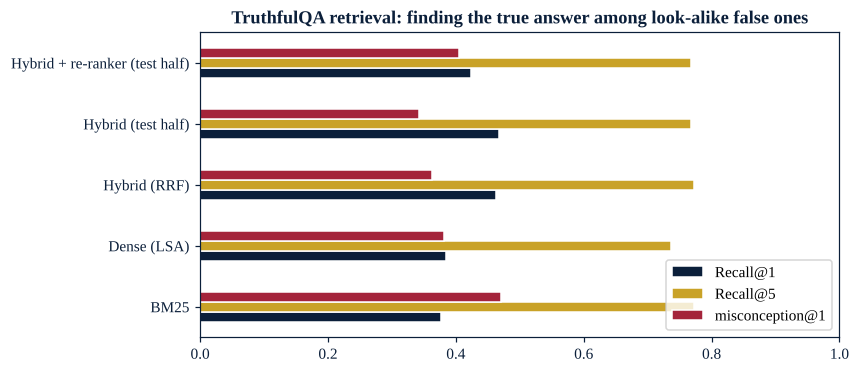

In [9]:
plot = pd.concat([res17, res17b])[["Recall@1", "Recall@5", "misconception@1"]]
ax = plot.plot.barh(figsize=(7.5, 3.6), color=[NAVY, GOLD, "#A4243B"], edgecolor="white")
ax.set_title("TruthfulQA retrieval: finding the true answer among look-alike false ones"); ax.set_xlim(0, 1)
plt.legend(loc="lower right"); plt.savefig(FIG/"s4_retrieval.png", bbox_inches="tight"); plt.show()

**Read this carefully:** a big share of top-1 results are the *false* answer to the same question. Retrieval finds text
that *matches*, not text that is *true*. A RAG system inherits whatever its corpus says — so curate the corpus.

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 18 — PolicyGPT: ingest and chunk a real PDF with metadata

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">Course syllabus PDF (20 pages) — NEP 2020 / UGC PDFs in class</span>
**Skills:** <span style="color:#6A3D9A">PDF parsing, chunking strategy, metadata</span>

In [10]:
from pypdf import PdfReader
PDF = pathlib.Path("../../syllabus/AlgoProfessor_AI_Scientist_Syllabus.pdf")
if not PDF.exists():   # e.g. running in Google Colab: fetch the PDF from the course repository
    PDF = fetch("https://raw.githubusercontent.com/drssnaiml1-cell/algoprofessor-ai-scientist/main/syllabus/AlgoProfessor_AI_Scientist_Syllabus.pdf", "AlgoProfessor_AI_Scientist_Syllabus.pdf")
reader = PdfReader(PDF)
pages = [(i + 1, re.sub(r"\s+", " ", p.extract_text() or "").strip()) for i, p in enumerate(reader.pages)]
print(f"{PDF.name}: {len(pages)} pages, {sum(len(t.split()) for _, t in pages):,} words")
print("page 3 starts:", pages[2][1][:160])

AlgoProfessor_AI_Scientist_Syllabus.pdf: 20 pages, 4,761 words
page 3 starts: AI Scientist — Hands-On Syllabus Sunday Edition · 30 Hours Hour 1 Teach Hour 2 Teach Hour 3 Build Lunch Hour 4 Build Hour 5 Build + review Tea 09:00 10:00 11:00


In [11]:
def chunk_pages(pages, size=90, overlap=30):
    """Sliding word windows inside each page, so every chunk keeps an exact page citation."""
    chunks = []
    for pg, text in pages:
        w = text.split()
        for start in range(0, max(1, len(w) - overlap), size - overlap):
            piece = " ".join(w[start:start + size])
            if len(piece.split()) > 15: chunks.append({"id": len(chunks), "page": pg, "text": piece})
    return pd.DataFrame(chunks)

chunks = chunk_pages(pages)
print("chunks:", len(chunks), "| words per chunk (median):", int(chunks.text.str.split().str.len().median()))
chunks.groupby("page").size().to_frame("chunks").T

chunks: 79 | words per chunk (median): 90


page,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
chunks,2,5,4,4,3,3,3,4,4,4,3,6,6,4,7,3,5,5,2,2


---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 19 — Cited Q&A API with abstention

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">Course syllabus PDF</span>
**Skills:** <span style="color:#6A3D9A">Hybrid search, grounded citations, abstention, FastAPI</span>

In [12]:
STOP = set("the a an of to in on for and or is are was what which who when how does do did be by with at as it this that from i my can we our you your there".split())
# question-phrasing words carry no facts: ignore them when checking whether the documents cover a question
STOP |= set("many much should must earn earns cover covers covered offer offers called use used apply applies made make get give after before during per each course learner learners".split())
def norm(w):
    w = w.strip(".,"); return w[:-1] if len(w) > 3 and w.endswith("s") and not w.endswith("ss") else w   # light stemming
ctok = lambda s: [norm(w) for w in re.findall(r"[a-z0-9%$:,.\-]+", s.lower()) if w.strip(".,") and w.strip(".,") not in STOP]
c_bm25 = BM25Okapi([ctok(t) for t in chunks.text])
c_tfidf = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2)).fit(chunks.text)
C3 = normalize(c_tfidf.transform(chunks.text))
chunk_sets = [set(ctok(t)) for t in chunks.text]
df_count = collections.Counter(w for st in chunk_sets for w in st)
OOV_IDF = math.log(len(chunks) + 1) + 1                       # a word the documents never use counts as maximally rare
idf = lambda w: math.log((len(chunks) + 1) / (1 + df_count[w])) + 1 if w in df_count else OOV_IDF

def retrieve(q, k=3):
    s_b = c_bm25.get_scores(ctok(q)); s_d = (normalize(c_tfidf.transform([q])) @ C3.T).toarray()[0]
    fused = rrf(s_b[None], s_d[None])[0]; top = np.argsort(-fused)[:k]
    return chunks.iloc[top].assign(score=fused[top])

def coverage(q, texts):
    """IDF-weighted share of the question's content words found in the retrieved chunks."""
    qw = ctok(q); found = set().union(*(set(ctok(t)) for t in texts))
    return sum(idf(w) for w in qw if w in found) / (sum(idf(w) for w in qw) + 1e-9)

def answer(q, k=3, min_cov=0.6):
    hits = retrieve(q, k); cov = coverage(q, hits.text)
    if cov < min_cov:
        return {"answer": "I can't find this in the documents.", "citations": [], "coverage": round(cov, 2), "abstained": True}
    qs = set(ctok(q)); best, best_score, best_page = "", -1, None
    for _, h in hits.iterrows():                                  # extractive answer: best 25-word window across the top chunks
        w = h.text.split()
        for i in range(0, max(1, len(w) - 24), 4):
            span = " ".join(w[i:i + 25]); sc = sum(idf(x) for x in qs & set(ctok(span)))
            if sc > best_score: best, best_score, best_page = span, sc, int(h.page)
    cites = [f"syllabus p.{best_page}"] + [f"syllabus p.{int(p)}" for p in hits.page.unique() if int(p) != best_page]
    return {"answer": best, "citations": cites, "coverage": round(cov, 2), "abstained": False}

for q in ["What is the programme fee in India?", "What is the hostel fee?"]:
    print(q, "\n ", json.dumps(answer(q), ensure_ascii=False)[:330], "\n")

What is the programme fee in India? 
  {"answer": "Sunday 30 Contact hours 18 Real-time build hours 30 Datasets (one per hour) 90+ Skills gained Programme fee INR 50,000 (Hyderabad & Shirdi, India) US$", "citations": ["syllabus p.1", "syllabus p.2", "syllabus p.18"], "coverage": 1.0, "abstained": false} 

What is the hostel fee? 
  {"answer": "I can't find this in the documents.", "citations": [], "coverage": 0.4, "abstained": true} 



Notice the second question: the word *fee* matches, but *hostel* never appears in the documents — the coverage
check makes the system **abstain** instead of answering with the programme fee. That one rule prevents a whole class of
hallucinations.

In [13]:
from fastapi import FastAPI
from fastapi.testclient import TestClient
from pydantic import BaseModel

app = FastAPI(title="PolicyGPT")
class Ask(BaseModel):
    question: str
    k: int = 3

@app.post("/ask")
def ask(req: Ask):
    return {"question": req.question, **answer(req.question, req.k)}

client = TestClient(app)
r = client.post("/ask", json={"question": "By what time must the GitHub submission be made?"})
print(r.status_code, json.dumps(r.json(), indent=1)[:500])

200 {
 "question": "By what time must the GitHub submission be made?",
 "answer": "30 Hours 10 GitHub Submission Policy: 18:00 Every Sunday Rule. Every learner submits that Sunday\u2019s project on GitHub by 18:00 local time on the same",
 "citations": [
  "syllabus p.17",
  "syllabus p.3"
 ],
 "coverage": 1.0,
 "abstained": false
}


Run it for real with `uvicorn policygpt_api:app --reload` after moving the functions into `src/policygpt_api.py`.

---
<span style="background:#0B1F3A;color:#C9A227;padding:3px 9px;border-radius:4px;font-weight:bold">BUILD</span>
## Hour 20 — Evaluate: golden set, faithfulness, abstention

**Dataset:** <span style="color:#1E7B5A;font-weight:bold">25-question golden set (20 answerable + 5 unanswerable)</span>
**Skills:** <span style="color:#6A3D9A">RAG evaluation, hallucination measurement, regression testing</span>

In [14]:
# 1) Tune the abstention threshold on a SEPARATE dev set, 2) report results on the untouched golden set
dev = [("Which dataset is used in Hour 6?", "Fashion-MNIST"), ("What is the Sunday 4 deliverable called?", "PolicyGPT"),
       ("When is the tea break?", "11:00"), ("Who is the course director?", "Satyanarayana"), ("How many job roles does the course map?", "16")]
dev_un = ["What is the parking fee?", "Are there weekday evening batches?", "What is the minimum age to enrol?"]
def dev_score(th):
    ok = [(not answer(q, min_cov=th)["abstained"]) and key.lower() in answer(q, min_cov=th)["answer"].lower() for q, key in dev]
    ok += [answer(q, min_cov=th)["abstained"] for q in dev_un]
    return np.mean(ok)
sweep = pd.Series({th: dev_score(th) for th in np.round(np.arange(0.3, 0.95, 0.05), 2)})
TH = float(sweep[sweep == sweep.max()].index[len(sweep[sweep == sweep.max()]) // 2])     # middle of the best plateau
print("dev accuracy by threshold:", sweep.round(2).to_dict()); print("chosen min_cov =", TH)

golden = [
 ("What is the programme fee in India?", "50,000"), ("What is the fee for learners in the USA?", "1,000"),
 ("By what time must the GitHub submission be made?", "18:00"), ("What is the maximum batch size per campus?", "30 learners"),
 ("How many mentors per learner in BUILD hours?", "1 mentor per 10"), ("When is the lunch break?", "12:15"),
 ("Which dataset is used for instruction tuning in Hour 13?", "dolly"), ("Which dataset is used for drift monitoring?", "Taxi"),
 ("What deduction applies to submissions made Monday to Wednesday?", "25%"), ("What overall score earns a Distinction?", "85%"),
 ("Which hour covers responsible AI and ethics?", "27"), ("How many contact hours does the course have?", "30"),
 ("What is the certificate number format?", "AP-AIS-L1"), ("Which campuses offer the course?", "Shirdi"),
 ("What is the Sunday 2 deliverable called?", "LeafDoctor"), ("What must never be committed to the repository?", "API keys"),
 ("What is the portfolio repository naming pattern?", "algoprofessor-ai-scientist-"), ("What should learners do in days 61 to 90 after the course?", "Apply to 30"),
 ("Which dataset is used in Hour 1?", "Adult"), ("Which framework is used for multi-agent orchestration?", "LangGraph"),
]
unanswerable = ["What is the hostel fee?", "Is there a scholarship for women?", "What is the refund policy?",
                "Which GPU model is installed in the lab?", "Who is the Prime Minister of India?"]

rows = []
for q, key in golden:
    a = answer(q, min_cov=TH); hits = retrieve(q)
    rows.append({"question": q, "retrieval hit@3": any(key.lower() in t.lower() for t in hits.text),
                 "answer correct": (not a["abstained"]) and key.lower() in a["answer"].lower(), "abstained": a["abstained"]})
for q in unanswerable:
    a = answer(q, min_cov=TH); rows.append({"question": q, "retrieval hit@3": None, "answer correct": a["abstained"], "abstained": a["abstained"]})
ev = pd.DataFrame(rows); ans = ev.iloc[:len(golden)]; una = ev.iloc[len(golden):]
summary = pd.Series({"retrieval hit@3 (answerable)": ans["retrieval hit@3"].mean(),
                     "answer contains gold fact (answerable)": ans["answer correct"].mean(),
                     "wrongly abstained (answerable)": ans["abstained"].mean(),
                     "correctly abstained (unanswerable)": una["abstained"].mean()}).round(3)
summary

dev accuracy by threshold: {0.3: 0.5, 0.35: 0.62, 0.4: 0.62, 0.45: 0.75, 0.5: 0.75, 0.55: 0.75, 0.6: 0.62, 0.65: 0.62, 0.7: 0.62, 0.75: 0.62, 0.8: 0.62, 0.85: 0.62, 0.9: 0.62}
chosen min_cov = 0.5


retrieval hit@3 (answerable)              0.95
answer contains gold fact (answerable)    0.60
wrongly abstained (answerable)            0.00
correctly abstained (unanswerable)        1.00
dtype: float64

In [15]:
# Faithfulness: share of answer words that appear in the cited chunks (extractive answers should score ~1.0)
def faithfulness(q):
    a = answer(q, min_cov=TH)
    if a["abstained"]: return np.nan
    ctx = " ".join(retrieve(q).text).lower(); words = re.findall(r"[a-z0-9]+", a["answer"].lower())
    return np.mean([w in ctx for w in words])
print("mean faithfulness:", round(np.nanmean([faithfulness(q) for q, _ in golden]), 3))
print("\nFailures to study:"); ev[(ev["answer correct"] == False)][["question", "retrieval hit@3", "abstained"]]

mean faithfulness: 1.0

Failures to study:


,question,retrieval hit@3,abstained
7,Which dataset is used for drift monitoring?,True,False
10,Which hour covers responsible AI and ethics?,True,False
12,What is the certificate number format?,True,False
14,What is the Sunday 2 deliverable called?,False,False
16,What is the portfolio repository naming pattern?,True,False
17,What should learners do in days 61 to 90 after...,True,False
18,Which dataset is used in Hour 1?,True,False
19,Which framework is used for multi-agent orches...,True,False


**Failure analysis.** Compare the two columns: when *retrieval hit@3* is True but the answer is wrong, the right page
was found and our simple extractive span-picker chose the wrong 25 words. That is exactly the job an LLM generator does
better — it reads the retrieved chunks and writes the answer, **with the same citations and the same abstention rule**.

**RAGAS in class:** with an LLM generator, measure *faithfulness* (are claims supported by context?) and
*answer relevance* with the `ragas` library. Keep this golden set in `tests/` and re-run it on every change —
a **regression test** for your RAG system. Grow it to 100 questions as a team.

---
<div style="background:#FFF3E0;border-left:6px solid #FF9933;padding:12px 16px;border-radius:6px">
<b>GitHub submission — by 18:00 local time today</b><br>
1. Copy this notebook into <code>P4-policygpt/notebooks/</code> of your portfolio repo.<br>
2. Move reusable functions into <code>P4-policygpt/src/</code>, save plots into <code>results/</code>.<br>
3. Update the project README (problem, dataset, method, results, how to run, limitations &amp; ethics, AI-assistant use).<br>
4. <code>git push origin main</code> → <code>git tag -a sunday-4 -m "Sunday 4 submission"</code> → <code>git push origin sunday-4</code><br>
5. Create a GitHub Release from the tag and submit the link on the AlgoProfessor form.
</div>